<a href="https://colab.research.google.com/github/nisanuruyumaz/Cat-Dog-Breed-Classifier/blob/main/Pet_Breed_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip -q install gradio scikit-learn matplotlib pillow requests

import os
import time
import json
import random
import copy
import html
import numpy as np
import torch
import torch.nn as nn
import torchvision
import matplotlib.pyplot as plt
import gradio as gr

from PIL import Image, ImageOps
from pathlib import Path
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from google.colab import drive

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("PyTorch:", torch.__version__)
print("Gradio:", gr.__version__)
print("Kullanılan cihaz:", device)


PyTorch: 2.14.1+cu130
Gradio: 6.31.0
Kullanılan cihaz: cuda


In [ ]:

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/PetBreedClassifier"
)

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = PROJECT_DIR / "best_pet_model.pth"
HISTORY_PATH = PROJECT_DIR / "training_history.json"
METRICS_PATH = PROJECT_DIR / "test_metrics.json"

print("Proje klasörü:", PROJECT_DIR)
print("Kayıtlı model var mı?", MODEL_PATH.exists())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Proje klasörü: /content/drive/MyDrive/PetBreedClassifier
Kayıtlı model var mı? True


In [ ]:

DATA_DIR = "/content/pet_data"

trainval_dataset = datasets.OxfordIIITPet(
    root=DATA_DIR,
    split="trainval",
    target_types="category",
    download=True
)

test_dataset_raw = datasets.OxfordIIITPet(
    root=DATA_DIR,
    split="test",
    target_types="category",
    download=True
)

class_names = trainval_dataset.classes
num_classes = len(class_names)

print("Eğitim + doğrulama:", len(trainval_dataset))
print("Test:", len(test_dataset_raw))
print("Cins sayısı:", num_classes)
print("İlk 5 cins:", class_names[:5])


Eğitim + doğrulama: 3680
Test: 3669
Cins sayısı: 37
İlk 5 cins: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle']


In [ ]:

IMG_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Eğitim için veri artırma kullanılır.
train_data = datasets.OxfordIIITPet(
    root=DATA_DIR,
    split="trainval",
    target_types="category",
    transform=train_transform,
    download=False
)

# Doğrulamada rastgele veri artırma kullanılmaz.
val_data = datasets.OxfordIIITPet(
    root=DATA_DIR,
    split="trainval",
    target_types="category",
    transform=test_transform,
    download=False
)

test_data = datasets.OxfordIIITPet(
    root=DATA_DIR,
    split="test",
    target_types="category",
    transform=test_transform,
    download=False
)

# Etiketleri okuyarak dengeli bir ayrım yap.
labels = [
    trainval_dataset[i][1]
    for i in range(len(trainval_dataset))
]

indices = np.arange(len(trainval_dataset))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=SEED,
    stratify=labels
)

train_subset = Subset(train_data, train_idx)
val_subset = Subset(val_data, val_idx)

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Eğitim:", len(train_subset))
print("Doğrulama:", len(val_subset))
print("Test:", len(test_data))


Eğitim: 2944
Doğrulama: 736
Test: 3669


In [ ]:

from torchvision.models import (
    resnet18,
    ResNet18_Weights
)

model = resnet18(
    weights=ResNet18_Weights.DEFAULT
)

# ResNet18'in son katmanını 37 cins için değiştir.
model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("Model: ResNet18")
print("Çıkış sınıfı:", num_classes)
print("Optimizer: Adam")
print("Loss: CrossEntropyLoss")


Model: ResNet18
Çıkış sınıfı: 37
Optimizer: Adam
Loss: CrossEntropyLoss


In [ ]:

EPOCHS = 5
history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_acc = 0.0
training_seconds = None

def evaluate_epoch(loader):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total


if MODEL_PATH.exists():

    print("💚 Kayıtlı model bulundu, yükleniyor...")

    state = torch.load(
        MODEL_PATH,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(state)
    model.eval()

    if HISTORY_PATH.exists():
        with open(HISTORY_PATH, "r") as f:
            history = json.load(f)

    print("🐾 Model başarıyla yüklendi!")

else:

    print("Kayıtlı model yok. Eğitim başlıyor...")

    start = time.perf_counter()

    for epoch in range(EPOCHS):
        model.train()

        running_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        val_loss, val_acc = evaluate_epoch(
            val_loader
        )

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(
                model.state_dict(),
                MODEL_PATH
            )

    training_seconds = time.perf_counter() - start

    with open(HISTORY_PATH, "w") as f:
        json.dump(history, f, indent=2)

    model.load_state_dict(
        torch.load(
            MODEL_PATH,
            map_location=device,
            weights_only=True
        )
    )

    model.eval()

    print("Eğitim süresi:", round(training_seconds, 2), "sn")
    print("En iyi doğrulama:", round(best_val_acc * 100, 2), "%")
    print("Model Drive'a kaydedildi!")


💚 Kayıtlı model bulundu, yükleniyor...
🐾 Model başarıyla yüklendi!


In [ ]:

model.eval()

y_true = []
y_pred = []

start = time.perf_counter()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy().tolist())
        y_pred.extend(
            predictions.cpu().numpy().tolist()
        )

test_seconds = time.perf_counter() - start

accuracy = accuracy_score(y_true, y_pred)

precision, recall, f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )
)

metrics = {
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1": float(f1),
    "test_seconds": float(test_seconds),
    "batch_average_seconds": float(
        test_seconds / len(test_data)
    )
}

with open(METRICS_PATH, "w") as f:
    json.dump(metrics, f, indent=2)

print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1 Score : {f1 * 100:.2f}%")
print(f"Test süresi: {test_seconds:.2f} sn")


Accuracy : 87.05%
Precision: 87.97%
Recall   : 87.02%
F1 Score : 86.84%
Test süresi: 19.19 sn


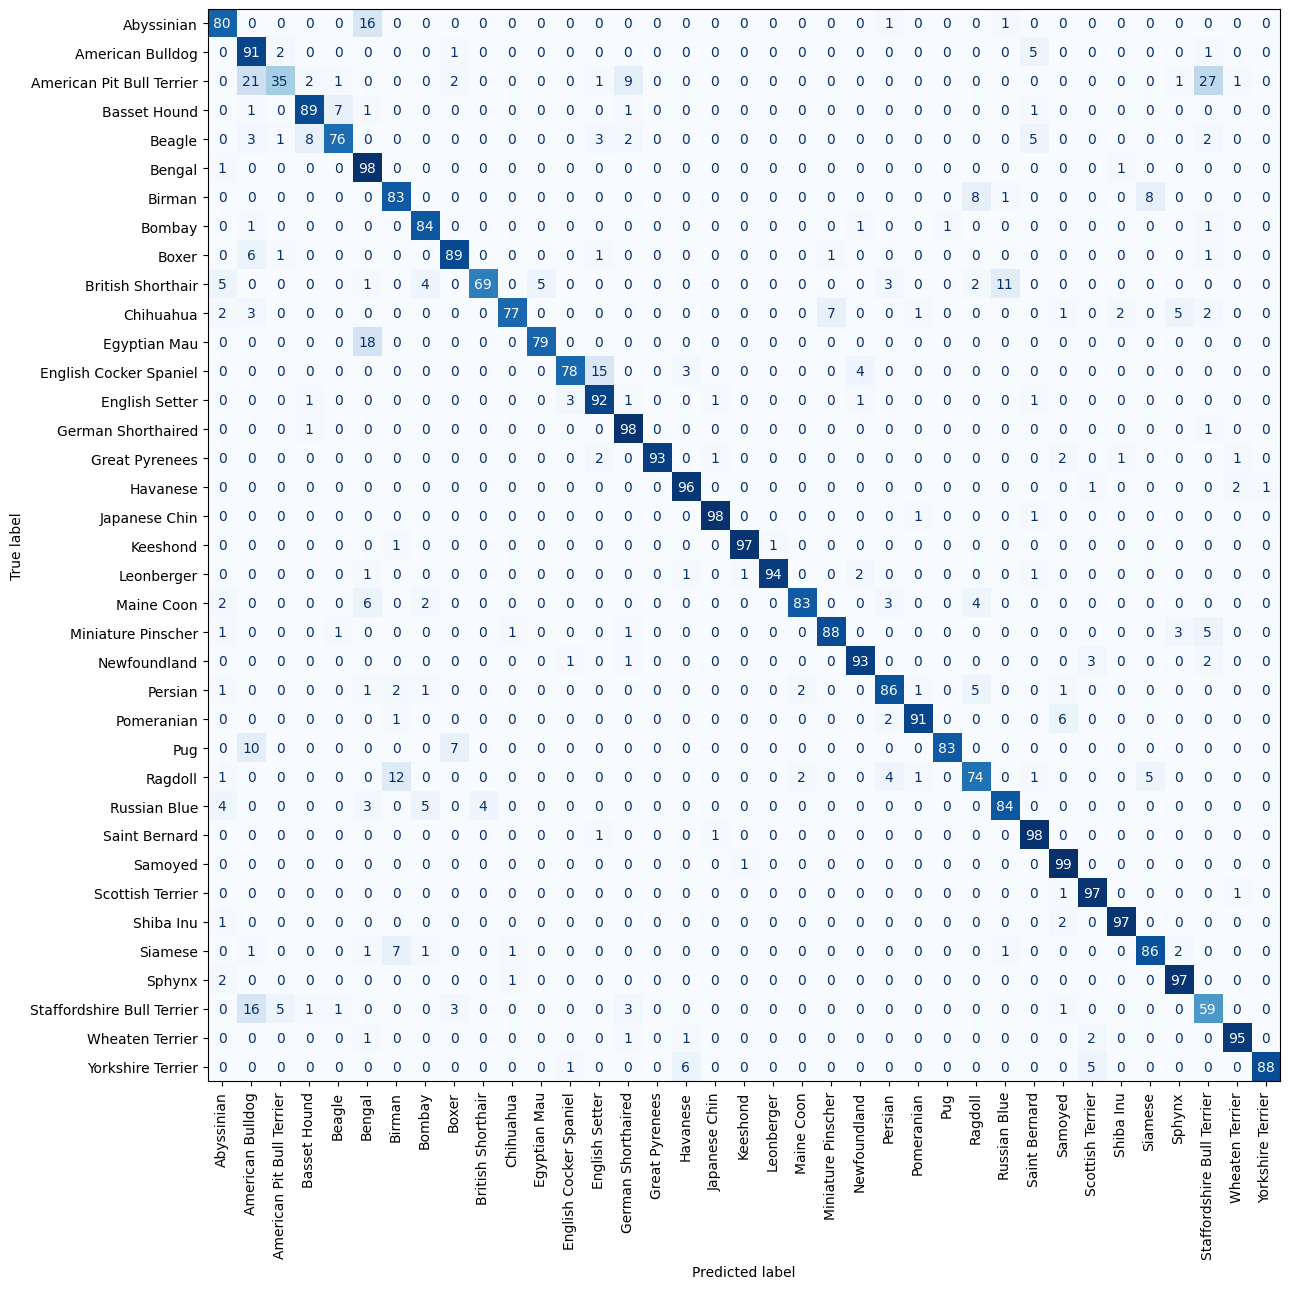

In [ ]:

# Eğitim geçmişi varsa grafikleri çiz.
if history.get("train_acc") and history.get("val_acc"):

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(
        history["train_acc"],
        label="Eğitim"
    )
    axes[0].plot(
        history["val_acc"],
        label="Doğrulama"
    )
    axes[0].set_title("Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(
        history["train_loss"],
        label="Eğitim"
    )
    axes[1].plot(
        history["val_loss"],
        label="Doğrulama"
    )
    axes[1].set_title("Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(
        PROJECT_DIR / "training_graphs.png",
        dpi=160
    )
    plt.show()

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(num_classes))
)

fig, ax = plt.subplots(figsize=(15, 13))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        c.replace("_", " ")
        for c in class_names
    ]
).plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

plt.tight_layout()
plt.savefig(
    PROJECT_DIR / "confusion_matrix.png",
    dpi=160
)
plt.show()


In [ ]:

# PAWSENSE - ŞEFFAF ARKA PLAN DÜZELTMESİ

from PIL import Image

def prepare_pet_image(image):

    image = image.convert("RGBA")

    # Şeffaf alanları beyaz arka planla birleştir
    background = Image.new(
        "RGBA",
        image.size,
        (255, 255, 255, 255)
    )

    image = Image.alpha_composite(
        background,
        image
    )

    return image.convert("RGB")


def predict_breed(image):

    if image is None:
        return {}

    image = prepare_pet_image(image)

    tensor = test_transform(image)
    tensor = tensor.unsqueeze(0).to(device)

    model.eval()

    with torch.inference_mode():
        outputs = model(tensor)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )[0]

    top_probs, top_indices = torch.topk(
        probabilities,
        k=5
    )

    results = {}

    for prob, idx in zip(top_probs, top_indices):
        breed = class_names[idx.item()]
        results[breed] = float(prob.item())

    return results


print("🐾 Görüntü işleme fonksiyonu güncellendi!")


🐾 Görüntü işleme fonksiyonu güncellendi!


In [ ]:

# ==========================================
# PAWSENSE - CİNS BİLGİLERİ VE FOTOĞRAFLAR
# ==========================================

# Oxford-IIIT Pet'teki kedi cinsleri
CAT_BREEDS = {
    "abyssinian", "bengal", "birman", "bombay",
    "british_shorthair", "egyptian_mau",
    "maine_coon", "persian", "ragdoll",
    "russian_blue", "siamese", "sphynx"
}

# Belirli cinsler için kısa tanıtımlar
SPECIAL_INFO = {
    "abyssinian": (
        "Meraklı, hareketli ve keşfetmeyi seven bir kedi.",
        ["Meraklı", "Aktif", "Oyuncu"]
    ),
    "bengal": (
        "Desenli tüyleri ve hareketli yapısıyla tanınan bir kedi.",
        ["Enerjik", "Meraklı", "Oyuncu"]
    ),
    "birman": (
        "Yumuşak tüyleri ve sakin yapısıyla tanınan bir kedi.",
        ["Sakin", "Sosyal", "Uzun tüylü"]
    ),
    "bombay": (
        "Parlak siyah tüyleriyle tanınan sosyal bir kedi.",
        ["Sosyal", "Meraklı", "Oyuncu"]
    ),
    "british_shorthair": (
        "Yuvarlak yüzü ve yoğun kısa tüyleriyle tanınır.",
        ["Sakin", "Kısa tüylü", "Uysal"]
    ),
    "egyptian_mau": (
        "Doğal benekli tüyleri ve çevikliğiyle tanınır.",
        ["Çevik", "Benekli", "Aktif"]
    ),
    "maine_coon": (
        "Büyük yapılı, uzun tüylü ve sosyal bir kedi.",
        ["Sosyal", "Uzun tüylü", "Oyuncu"]
    ),
    "persian": (
        "Uzun tüyleri ve sakin mizacıyla tanınan bir kedi.",
        ["Sakin", "Uzun tüylü", "Sevecen"]
    ),
    "ragdoll": (
        "İnsanlarla yakınlığı seven, sakin bir kedi.",
        ["Sakin", "Sosyal", "Sevecen"]
    ),
    "russian_blue": (
        "Gri-mavi kısa tüyleriyle tanınan zarif bir kedi.",
        ["Kısa tüylü", "Zarif", "Oyuncu"]
    ),
    "siamese": (
        "Sesli iletişimi ve sosyal yapısıyla tanınır.",
        ["İletişimci", "Sosyal", "Aktif"]
    ),
    "sphynx": (
        "Çok az tüylü görünümüyle tanınan sosyal bir kedi.",
        ["Sosyal", "Oyuncu", "Az tüylü"]
    ),
    "beagle": (
        "Güçlü koku alma duyusu ve meraklı yapısıyla tanınır.",
        ["Meraklı", "Hareketli", "Sosyal"]
    ),
    "boxer": (
        "Hareketli ve oyuncu yapısıyla tanınan bir köpek.",
        ["Enerjik", "Oyuncu", "Sosyal"]
    ),
    "chihuahua": (
        "Küçük yapılı ve canlı bir köpek cinsidir.",
        ["Küçük", "Canlı", "Dikkatli"]
    ),
    "english_cocker_spaniel": (
        "Hareketli ve arkadaş canlısı bir köpek.",
        ["Sosyal", "Aktif", "Oyuncu"]
    ),
    "german_shepherd": (
        "Öğrenmeye açık ve hareketli bir köpek cinsidir.",
        ["Öğrenmeye açık", "Aktif", "Dikkatli"]
    ),
    "great_pyrenees": (
        "Büyük yapılı, yoğun tüylü bir köpek cinsidir.",
        ["Büyük", "Yoğun tüylü", "Sakin"]
    ),
    "havanese": (
        "Küçük, uzun tüylü ve sosyal bir köpek.",
        ["Küçük", "Sosyal", "Oyuncu"]
    ),
    "leonberger": (
        "Büyük yapılı, uzun tüylü bir köpek cinsidir.",
        ["Büyük", "Uzun tüylü", "Sosyal"]
    ),
    "miniature_pinscher": (
        "Küçük ve oldukça hareketli bir köpek.",
        ["Küçük", "Enerjik", "Dikkatli"]
    ),
    "newfoundland": (
        "Büyük yapılı, güçlü ve yoğun tüylü bir köpek.",
        ["Büyük", "Güçlü", "Sakin"]
    ),
    "pomeranian": (
        "Küçük yapılı, kabarık tüylü ve canlı bir köpek.",
        ["Küçük", "Kabarık tüylü", "Canlı"]
    ),
    "pug": (
        "Kısa burunlu, küçük ve sosyal bir köpek.",
        ["Küçük", "Sosyal", "Oyuncu"]
    ),
    "samoyed": (
        "Beyaz, yoğun tüyleriyle tanınan hareketli bir köpek.",
        ["Yoğun tüylü", "Sosyal", "Aktif"]
    ),
    "shiba_inu": (
        "Dik kulakları ve kıvrık kuyruğuyla tanınan bir köpek.",
        ["Çevik", "Dikkatli", "Bağımsız"]
    ),
    "wheaten_terrier": (
        "Yumuşak tüyleriyle tanınan hareketli bir köpek.",
        ["Aktif", "Oyuncu", "Sosyal"]
    ),
    "yorkshire_terrier": (
        "Küçük yapılı, uzun tüylü bir köpek cinsidir.",
        ["Küçük", "Canlı", "Uzun tüylü"]
    )
}

def breed_key(name):
    return name.lower().replace(" ", "_").replace("-", "_")

breed_info = {}

for breed in class_names:
    key = breed_key(breed)
    is_cat = key in CAT_BREEDS

    if key in SPECIAL_INFO:
        description, traits = SPECIAL_INFO[key]
    else:
        species = "kedi" if is_cat else "köpek"
        description = (
            f"{breed.replace('_', ' ').title()}, "
            f"Oxford-IIIT Pet veri setinde bulunan "
            f"bir {species} cinsidir."
        )
        traits = [
            "Kedi" if is_cat else "Köpek",
            "Oxford-IIIT Pet"
        ]

    breed_info[key] = {
        "description": description,
        "traits": traits,
        "species": "Kedi" if is_cat else "Köpek"
    }

# Eğitim/doğrulama havuzundan örnek fotoğraflar
breed_photos = {}

for i in range(len(trainval_dataset)):
    image, label = trainval_dataset[i]
    breed = class_names[label]
    key = breed_key(breed)

    if key not in breed_photos:
        breed_photos[key] = image.copy()

    if len(breed_photos) == num_classes:
        break

print("Cins bilgi sayısı:", len(breed_info))
print("Örnek fotoğraf sayısı:", len(breed_photos))


Cins bilgi sayısı: 37
Örnek fotoğraf sayısı: 37


In [ ]:

# ==========================================
# PAWSENSE - SONUÇ TASARIMI
# ==========================================


def create_prediction_bars(predictions):

    if not predictions:
        return "<p>Henüz analiz yapılmadı.</p>"

    top_probability = max(predictions.values())

    result = """
    <div class="ps-result-card">
        <h2>🐾 Analiz Sonucun</h2>
        <p>En olası 5 cins:</p>
    """

    for rank, (breed, prob) in enumerate(
        predictions.items(), start=1
    ):
        percentage = max(
            0, min(100, float(prob) * 100)
        )

        name = html.escape(
            breed.replace("_", " ").title()
        )

        result += f"""
        <div class="ps-prediction">
            <div class="ps-prediction-heading">
                <span>{rank}. {name}</span>
                <strong>{percentage:.2f}%</strong>
            </div>

            <div class="ps-progress">
                <div class="ps-progress-fill"
                     style="width:{percentage:.2f}%">
                </div>
            </div>
        </div>
        """

    if top_probability < 0.40:
        result += """
        <div style="
            background:#FFF3DF;
            color:#805C2C;
            padding:16px;
            border-radius:15px;
            margin-top:20px;
        ">
            <strong>⚠️ Belirsiz Tahmin</strong>
            <p style="color:#805C2C;">
                Model bu fotoğrafta net bir
                tahmin oluşturamadı.
                Fotoğraf desteklenmeyen bir
                cinse ait olabilir.
            </p>
        </div>
        """

    result += """
        <p class="ps-note">
            Tahminler yalnızca desteklenen
            37 cins arasından yapılır.
            Yüksek olasılık bile kesin
            cins doğrulaması değildir.
        </p>
    </div>
    """

    return result


def create_breed_card(predictions):

    if not predictions:
        return "<p>Henüz cins bilgisi yok.</p>"

    top_breed = max(
        predictions, key=predictions.get
    )

    key = breed_key(top_breed)
    info = breed_info[key]

    name = html.escape(
        top_breed.replace("_", " ").title()
    )

    description = html.escape(
        info["description"]
    )

    tags = "".join(
        f'<span class="ps-tag">{html.escape(t)}</span>'
        for t in info["traits"]
    )

    return f"""
    <div class="ps-result-card">
        <h2>💚 {name}</h2>
        <p class="ps-species">
            {html.escape(info["species"])} cinsi
        </p>
        <p>{description}</p>
        <div class="ps-tags">{tags}</div>
        <p class="ps-note">
            Bunlar cinsin genel özellikleridir.
            Her hayvanın karakteri farklı olabilir.
        </p>
    </div>
    """


def predict_with_info(image):

    if image is None:
        return (
            "<p>Önce fotoğraf yükle. 🐾</p>",
            None,
            ""
        )

    predictions = predict_breed(image)

    top_breed = max(
        predictions, key=predictions.get
    )

    photo = breed_photos.get(
        breed_key(top_breed)
    )

    bars = create_prediction_bars(
        predictions
    )

    info_card = create_breed_card(
        predictions
    )

    return bars, photo, info_card


print("💚 Tahmin ve bilgi kartları hazır!")


💚 Tahmin ve bilgi kartları hazır!


In [ ]:

# ==========================================
# PAWSENSE - TASARIM
# ==========================================

PAWSENSE_CSS = """
.gradio-container {
    --body-background-fill: #F5F3EB;
    --block-background-fill: #FFFFFF;
    --block-label-background-fill: #E6EFE5;
    --block-label-text-color: #426A55;
    --body-text-color: #426A55;
    --body-text-color-subdued: #718474;
    --input-background-fill: #FFFFFF;
    --border-color-primary: #D9E5D8;
    --color-accent: #72977C;
    --color-accent-soft: #E6EFE5;

    background: #F5F3EB !important;
    color: #426A55 !important;
    max-width: 1100px !important;
    margin: auto !important;
}

#ps-header {
    text-align: center;
    padding: 36px 15px 20px;
}

#ps-header h1 {
    color: #426A55 !important;
    font-size: clamp(28px, 5vw, 48px);
    font-weight: 800;
    line-height: 1.2;
}

#ps-header p {
    color: #718474;
    font-size: 17px;
}

.ps-brand {
    font-size: 26px;
    color: #567A62;
    font-weight: 800;
    margin-bottom: 24px;
}

.gradio-container h2,
.gradio-container h3 {
    color: #426A55 !important;
}

#ps-upload {
    background: white !important;
    border: 2px dashed #A7C1AB !important;
    border-radius: 22px !important;
}

#ps-upload .image-container {
    background: white !important;
}

#ps-analyze {
    background: #72977C !important;
    color: white !important;
    border: none !important;
    border-radius: 30px !important;
    font-size: 18px !important;
    font-weight: 700 !important;
    min-height: 55px;
    transition: transform .25s, background .25s;
}

#ps-analyze:hover {
    background: #567A62 !important;
    transform: translateY(-3px);
}

#ps-clear {
    border-radius: 30px !important;
}

.ps-result-card {
    background: white;
    border-radius: 22px;
    padding: 24px;
    margin: 12px 0;
    box-shadow: 0 6px 22px rgba(60,90,65,.08);
    animation: ps-appear .5s ease;
}

.ps-result-card h2 {
    color: #426A55 !important;
    margin-bottom: 12px;
}

.ps-result-card p {
    color: #718474;
    line-height: 1.7;
}

.ps-prediction {
    margin: 20px 0;
}

.ps-prediction-heading {
    display: flex;
    justify-content: space-between;
    gap: 12px;
    margin-bottom: 8px;
    color: #426A55;
    font-weight: 600;
}

.ps-progress {
    height: 12px;
    background: #E3EBE2;
    border-radius: 30px;
    overflow: hidden;
}

.ps-progress-fill {
    height: 100%;
    background: #72977C;
    border-radius: 30px;
    animation: ps-grow .8s ease-out;
}

.ps-tag {
    display: inline-block;
    padding: 8px 14px;
    margin: 5px 5px 5px 0;
    background: #E6EFE5;
    color: #426A55;
    border-radius: 30px;
    font-size: 14px;
}

.ps-note {
    font-size: 12px;
    margin-top: 20px;
}

.ps-species {
    font-weight: 600;
}

.ps-stats {
    display: flex;
    flex-wrap: wrap;
    gap: 14px;
    justify-content: center;
    margin: 24px 0;
}

.ps-stat {
    background: white;
    border-radius: 18px;
    padding: 20px;
    text-align: center;
    flex: 1 1 140px;
    box-shadow: 0 4px 14px rgba(60,90,65,.06);
}

.ps-stat strong {
    display: block;
    color: #426A55;
    font-size: 23px;
}

.ps-stat span {
    color: #718474;
    font-size: 13px;
}

.ps-steps {
    display: grid;
    grid-template-columns: repeat(3, 1fr);
    gap: 15px;
}

.ps-step {
    background: white;
    padding: 22px;
    border-radius: 20px;
    text-align: center;
}

.ps-step strong {
    display: block;
    color: #426A55;
    margin-bottom: 8px;
}

.ps-step p {
    color: #718474;
    font-size: 14px;
}

.ps-footer {
    text-align: center;
    padding: 35px 15px;
    color: #718474;
}

.ps-heart {
    display: inline-block;
    animation: ps-heartbeat 1.5s ease-in-out infinite;
}

@keyframes ps-appear {
    from {
        opacity: 0;
        transform: translateY(12px);
    }
    to {
        opacity: 1;
        transform: translateY(0);
    }
}

@keyframes ps-grow {
    from { width: 0; }
}

@keyframes ps-heartbeat {
    0%, 100% { transform: scale(1); }
    50% { transform: scale(1.15); }
}

@media (max-width: 600px) {
    #ps-header { padding: 20px 8px; }
    .ps-steps { grid-template-columns: 1fr; }
    .ps-result-card { padding: 16px; }
}
"""

print("🌿 PawSense tasarımı hazır!")


🌿 PawSense tasarımı hazır!


In [ ]:

# ==========================================
# PAWSENSE - DESTEKLENEN 37 CİNS
# ==========================================

def get_supported_breeds_html():

    cat_names = []
    dog_names = []

    for breed in class_names:

        key = breed_key(breed)

        name = html.escape(
            breed.replace("_", " ").title()
        )

        if key in CAT_BREEDS:
            cat_names.append(name)
        else:
            dog_names.append(name)

    def make_tags(names):
        return "".join(
            f'<span class="ps-tag">{name}</span>'
            for name in names
        )

    return f"""
    <div class="ps-result-card">

        <h2>🐾 PawSense Hangi Cinsleri Tanıyor?</h2>

        <p>
            Modelimiz 37 farklı kedi ve köpek
            cinsi üzerinde eğitilmiştir.
        </p>

        <h3>🐱 Kedi Cinsleri ({len(cat_names)})</h3>
        <div class="ps-tags">
            {make_tags(cat_names)}
        </div>

        <h3>🐶 Köpek Cinsleri ({len(dog_names)})</h3>
        <div class="ps-tags">
            {make_tags(dog_names)}
        </div>

        <p class="ps-note">
            ⚠️ Bu listede olmayan cinsler
            model tarafından güvenilir şekilde
            tanınamaz. Model yine de 37 cinsten
            birini tahmin edebilir.
        </p>

    </div>
    """

SUPPORTED_BREEDS_HTML = get_supported_breeds_html()

print("🐾 Desteklenen cins listesi hazır!")
print("Toplam:", len(class_names))


🐾 Desteklenen cins listesi hazır!
Toplam: 37


In [ ]:

# ==========================================
# PAWSENSE - TAM WEB UYGULAMASI
# ==========================================

# Karşılama görselleri:
# Veri setinden bir kedi ve bir köpek örneği
cat_example = next(
    breed_photos[k]
    for k in breed_photos
    if k in CAT_BREEDS
)

dog_example = next(
    breed_photos[k]
    for k in breed_photos
    if k not in CAT_BREEDS
)

# Test başarısı dinamik olarak gösterilir
accuracy_text = f"%{accuracy * 100:.2f}"

with gr.Blocks(
    title="PawSense | Pet Breed AI"
) as pawsense_demo:

    # 1. KARŞILAMA
    gr.HTML("""
    <div id="ps-header">
        <div class="ps-brand">
            🐾 PawSense
        </div>

        <h1>
            Minik dostunu daha yakından tanı! 🐾
        </h1>

        <p>
            Bir fotoğraf yükle,
            yapay zekâ ile cinsini keşfet.
        </p>

        <p>
            🐱 <span class="ps-heart">💚</span> 🐶
        </p>
    </div>
    """)

    # 2. GERÇEK HAYVAN FOTOĞRAFLARI
    with gr.Row():
        gr.Image(
            value=cat_example,
            label="🐱 Sevimli Dostlarımız",
            interactive=False,
            height=230
        )

        gr.Image(
            value=dog_example,
            label="🐶 Sadık Dostlarımız",
            interactive=False,
            height=230
        )

    # 3. MODEL İSTATİSTİKLERİ
    gr.HTML(f"""
    <div class="ps-stats">
        <div class="ps-stat">
            <strong>37</strong>
            <span>Farklı cins</span>
        </div>

        <div class="ps-stat">
            <strong>{accuracy_text}</strong>
            <span>Test doğruluğu</span>
        </div>

        <div class="ps-stat">
            <strong>ResNet18</strong>
            <span>Yapay zekâ modeli</span>
        </div>
    </div>
    """)

    # 4. FOTOĞRAF YÜKLEME
    gr.Markdown(
        "## 🐱 🐶 Dostunun fotoğrafını yükle"
    )

    gr.Markdown(
        "Kedinin veya köpeğinin fotoğrafını "
        "seçerek analiz etmeye başla."
    )

    pet_image = gr.Image(
        type="pil",
        sources=["upload", "webcam"],
        label="📸 Kedi veya Köpek Fotoğrafı",
        height=320,
        elem_id="ps-upload"
    )

    # 5. BUTONLAR
    with gr.Row():
        analyze_button = gr.Button(
            "🐾 Dostumu Tanı 💚",
            variant="primary",
            elem_id="ps-analyze"
        )

        clear_button = gr.Button(
            "🔄 Yeni Fotoğraf",
            elem_id="ps-clear"
        )

    # 6. TAHMİN SONUÇLARI
    gr.Markdown("## 🌿 Analiz Sonuçları")

    prediction_output = gr.HTML(
        value="""
        <div class="ps-result-card">
            <p>
                🐾 Henüz analiz yapılmadı.
                Fotoğrafını yükleyip
                Dostumu Tanı butonuna bas.
            </p>
        </div>
        """
    )

    # 7. CİNS BİLGİ KARTI
    gr.Markdown("## 💚 Minik Dostunu Tanı")

    breed_photo_output = gr.Image(
        label="🐾 Tahmin edilen cinsin örnek fotoğrafı",
        interactive=False,
        height=280,
        visible=False
    )

    breed_info_output = gr.HTML(
        value="""
        <div class="ps-result-card">
            <p>
                🌿 Cins bilgileri analizden sonra
                burada görünecek.
            </p>
        </div>
        """
    )

    # 8. MODEL BAĞLANTISI
    def run_analysis(image):
        bars, photo, info = predict_with_info(image)

        return (
            bars,
            gr.update(
                value=photo,
                visible=photo is not None
            ),
            info
        )

    analyze_button.click(
        fn=run_analysis,
        inputs=pet_image,
        outputs=[
            prediction_output,
            breed_photo_output,
            breed_info_output
        ]
    )

    # 9. YENİ FOTOĞRAF BUTONU
    def reset_analysis():
        return (
            None,
            "",
            gr.update(
                value=None,
                visible=False
            ),
            ""
        )

    clear_button.click(
        fn=reset_analysis,
        inputs=[],
        outputs=[
            pet_image,
            prediction_output,
            breed_photo_output,
            breed_info_output
        ]
    )

    # 10. NASIL ÇALIŞIR?


    # DESTEKLENEN CİNSLER

    with gr.Accordion(
        "🐱🐶 Desteklenen 37 Cinsi Gör",
        open=False
    ):
        gr.HTML(SUPPORTED_BREEDS_HTML)


    gr.Markdown("## 🐾 PawSense Nasıl Çalışır?")

    gr.HTML("""
    <div class="ps-steps">

        <div class="ps-step">
            <strong>📸 1. Fotoğraf Yükle</strong>
            <p>
                Kedi veya köpek fotoğrafını seç.
            </p>
        </div>

        <div class="ps-step">
            <strong>💚 2. Dostumu Tanı</strong>
            <p>
                Yapay zekâ fotoğrafı analiz etsin.
            </p>
        </div>

        <div class="ps-step">
            <strong>🌿 3. Cinsini Keşfet</strong>
            <p>
                Tahminleri ve cins bilgilerini incele.
            </p>
        </div>

    </div>
    """)

    # 11. MODEL BAŞARISI
    gr.Markdown("## 🧠 Yapay Zekâ Modelimiz")

    gr.Markdown(f"""
    | Özellik | Değer |
    |---|---|
    | Model | ResNet18 |
    | Veri seti | Oxford-IIIT Pet |
    | Cins sayısı | 37 |
    | Accuracy | %{accuracy * 100:.2f} |
    | Precision | %{precision * 100:.2f} |
    | Recall | %{recall * 100:.2f} |
    | F1 Score | %{f1 * 100:.2f} |
    | Kütüphane | PyTorch |
    """)

    # 12. ALT BİLGİ
    gr.HTML("""
    <div class="ps-footer">
        🐾 <strong>PawSense</strong>
        <p>
            Yapay Zekâ Destekli Kedi ve Köpek
            Cinsi Tanıma Sistemi
        </p>
        <p>
            Computer Vision • Deep Learning • ResNet18
        </p>
    </div>
    """)

print("🐾 PawSense uygulaması hazır!")


🐾 PawSense uygulaması hazır!


In [ ]:

# ==========================================
# PAWSENSE - UYGULAMAYI BAŞLAT
# ==========================================

pawsense_demo.launch(
    share=True,
    debug=True,
    theme=gr.themes.Soft(
        primary_hue="green",
        neutral_hue="stone"
    ),
    css=PAWSENSE_CSS
)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://ed40ffaca852e72c5c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# PAWSENSE - MODEL KONTROLÜ

print("Model dosyası:", MODEL_PATH)
print("Model mevcut mu?", MODEL_PATH.exists())

print("\nSınıf sayısı:", len(class_names))

print("\nİlk 10 sınıf:")
for i, name in enumerate(class_names[:10]):
    print(i, name)

print("\nSon 10 sınıf:")
for i, name in enumerate(class_names[-10:], start=len(class_names)-10):
    print(i, name)

print("\nTest doğruluğu:")
print(f"%{accuracy * 100:.2f}")

print("\nModel çıkış sayısı:")
print(model.fc.out_features)
